[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/phildani7/why-book-of-deep-learning-part-2/blob/main/notebooks/ch35_LabCh35_TinyGPT.ipynb)

**The Why Book of Deep Learning, Part 2** by Dr. Philemon Paul Daniel

**Chapter 35: Building a Small GPT** (Part VIII: Language Models).

* Read this chapter free online: [www.micyaai.com/books/why-deep-learning-2/read.html?ch=35](https://www.micyaai.com/books/why-deep-learning-2/read.html?ch=35)
* Part 1 of the book and its notebooks: [github.com/phildani7/why-book-of-deep-learning-part-1](https://github.com/phildani7/why-book-of-deep-learning-part-1)
* All the notebooks for the book: [github.com/phildani7/why-book-of-deep-learning-part-2](https://github.com/phildani7/why-book-of-deep-learning-part-2)

Tested with TensorFlow 2.21 and Keras 3.14 on a laptop CPU (about five minutes or less). In Colab:
*Runtime > Run all*. It runs on the free CPU runtime; a GPU runtime works too and is usually faster, but the
printed timings and some last digits will differ from the saved outputs.

---


# Lab Ch35 - TinyGPT
## A complete language model, built from layers you know, trained on a laptop in a few minutes

This lab goes with **Chapter 35** of *The Why Book of Deep Learning, Part 2*.

A GPT is the transformer block of Chapter 23, stacked, with a mask so that no position sees the future and a
loss that asks one question at every position: *what comes next?* In this lab you build one, count every
parameter before Keras does, check that its first loss is the loss of a blind guess, prove that it cannot
peek, and watch its writing go from noise to something shaped like English.

**TinyGPT** is the book's own language model. Later chapters (36, 38, 40, 41, 43, 44, 60) rebuild exactly this
model, so three functions in this notebook are written to be copied word for word: `load_corpus()`,
`build_tinygpt()` and `generate()`.

| TinyGPT | value |
|---|---|
| kind | decoder-only, pre-norm |
| width d | 64 |
| heads | 4 (each 16 wide) |
| blocks | 2 |
| feed-forward width | 256 |
| context T | 64 characters |
| vocabulary V | 39 characters |
| positions | a learnt table |
| output head | its own weights (not tied to the token table) |

### What you will be able to do afterwards

| Skill | Where |
|---|---|
| Turn raw text into ids, and into (input, target) pairs shifted by one | Steps 2 to 6 |
| Say what loss a model with no context, or one character of context, can reach | Step 4 |
| Count a GPT's parameters by hand and check the count against Keras | Steps 7 and 8 |
| Follow the shapes from `(batch, T)` to `(batch, T, V)` | Step 9 |
| Draw the causal mask and prove that nothing leaks from the future | Steps 10 and 11 |
| Check the first loss against ln V, and read a loss as a perplexity | Steps 12 and 16 |
| Train, sample, and read what the samples say about what was learnt | Steps 13 to 17 |
| Recognise a model that cheats and a model that memorises | Steps 18 and 19 |

### The rule of this lab: predict, then run

Every step asks you to **write down a prediction before you run the cell**. A wrong prediction that you
understand afterwards is worth more than a right one you guessed.

> **Runtime:** about four to five minutes on a laptop CPU, most of it in Step 14. No GPU is needed. The only
> download is the IMDB data set that ships with Keras (`keras.datasets.imdb`).

> **Honest scale:** this is a miniature. It has about a hundred thousand parameters and reads about three and a
> half million characters. It will learn spelling and some local grammar. It will not learn facts or hold a
> thought. Step 20 puts it beside GPT-2 small (2019), which is the same design with bigger numbers.

---
## Step 1 - Imports and one seed

In [1]:
import os, time
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 35
keras.utils.set_random_seed(SEED)
rng = np.random.default_rng(SEED)
np.set_printoptions(precision=3, suppress=True)
t_start = time.time()
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)

TensorFlow 2.21.0 | Keras 3.14.1


---
## Step 2 - The corpus: IMDB reviews, turned back into text

Keras ships the IMDB film reviews as lists of word ids. `load_corpus()` turns the first 3,000 training reviews
back into lowercase text, drops the leftover `br` tokens (they were HTML line breaks) and keeps only the 39
characters of `ALPHABET`. The punctuation was already removed by whoever built the data set, so the text
reads like one long breathless sentence. That is fine for our purpose.

The function returns a list of reviews, so that we can split by review later.

> **Predict:** a review is a few hundred words. Roughly how many characters will 3,000 reviews hold: tens of
> thousands, hundreds of thousands, or millions?

In [2]:
ALPHABET = "\n '0123456789abcdefghijklmnopqrstuvwxyz"   # newline, space, apostrophe, digits, letters


def load_corpus(n_reviews=3000):
    """IMDB reviews from keras.datasets, decoded to lowercase text. Returns a list of strings, one per review.
    Only the characters in ALPHABET survive; everything else is dropped."""
    (x_train, _), _ = keras.datasets.imdb.load_data()
    word_index = keras.datasets.imdb.get_word_index()
    id_to_word = {i + 3: w for w, i in word_index.items()}      # ids 0, 1, 2 are pad, start, unknown
    keep = set(ALPHABET) - {"\n"}
    reviews = []
    for ids in x_train[:n_reviews]:
        words = [id_to_word.get(i, "") for i in ids if i >= 3]
        line = " ".join(w for w in words if w and w != "br").lower()
        line = "".join(ch for ch in line if ch in keep)
        reviews.append(" ".join(line.split()))
    return reviews


reviews = load_corpus()
n_chars = sum(len(r) for r in reviews)
print(f"{len(reviews):,} reviews, {n_chars:,} characters, {n_chars / len(reviews):,.0f} per review on average")
print()
print(reviews[0][:300], "...")

3,000 reviews, 3,890,907 characters, 1,297 per review on average

this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being there robert redford's is an amazing actor and now the same being director norman's father came from the same scottish island as myself so i loved the  ...


---
## Step 3 - Characters to integers and back

Chapter 33 is about tokenizers. Here we use the smallest one there is: **one character, one id**. The
vocabulary is the 39 characters of `ALPHABET`. Id 0 is the newline, which we put at the end of every review,
so the model also has a way to say "this review is over".

> **Predict:** which id does the letter `a` get? (Count along `ALPHABET`: newline, space, apostrophe, ten
> digits, then the letters.)

In [3]:
V = len(ALPHABET)
char_to_id = {ch: i for i, ch in enumerate(ALPHABET)}


def encode(text):
    """text -> array of ids. Characters outside ALPHABET are dropped."""
    return np.array([char_to_id[ch] for ch in text.lower() if ch in char_to_id], dtype=np.int32)


def decode(ids):
    """ids -> text."""
    return "".join(ALPHABET[int(i)] for i in ids)


print("V =", V)
print("id of 'a':", char_to_id["a"], "| id of space:", char_to_id[" "], "| id of newline:", char_to_id["\n"])
ids = encode("a great film")
print("encode('a great film') =", ids)
print("decode(...)            =", repr(decode(ids)))
assert decode(encode("a great film")) == "a great film"

V = 39
id of 'a': 13 | id of space: 1 | id of newline: 0
encode('a great film') = [13  1 19 30 17 13 32  1 18 21 24 25]
decode(...)            = 'a great film'


---
## Step 4 - Split by review, then set two baselines to beat

The first 90% of the reviews are for training and the last 10% for validation. We split **by review**, so no
validation character ever appears in a training window.

Before building anything, ask what a much simpler predictor could do. Loss here is always cross-entropy in
nats per character: the average of −ln(probability given to the right next character).

* **Blind guess:** every character equally likely. Loss = ln V.
* **Letter frequencies (no context):** always answer with the overall frequency table.
* **Bigram table (one character of context):** a 39 × 39 table of counts, "after `t`, what follows?".

> **Predict:** ln 39. Then guess how much of the gap between a blind guess and perfect knowledge the frequency
> table closes.

In [4]:
n_train_reviews = int(len(reviews) * 0.9)
train_ids = encode("\n".join(reviews[:n_train_reviews]) + "\n")
val_ids = encode("\n".join(reviews[n_train_reviews:]) + "\n")
print(f"train: {len(train_ids):,} characters   validation: {len(val_ids):,} characters")

loss_blind = float(np.log(V))

counts = np.bincount(train_ids, minlength=V).astype(np.float64)
p_uni = counts / counts.sum()
loss_unigram = float(-np.log(p_uni[val_ids]).mean())

pair = np.zeros((V, V))
np.add.at(pair, (train_ids[:-1], train_ids[1:]), 1)
p_bi = (pair + 0.01) / (pair + 0.01).sum(axis=1, keepdims=True)     # 0.01 keeps unseen pairs off zero
loss_bigram = float(-np.log(p_bi[val_ids[:-1], val_ids[1:]]).mean())

print(f"blind guess        ln {V} = {loss_blind:.3f}")
print(f"letter frequencies       = {loss_unigram:.3f}   (validation text)")
print(f"bigram table             = {loss_bigram:.3f}   (validation text)")
top = np.argsort(-p_uni)[:6]
print("commonest characters:", ", ".join(f"{ALPHABET[i]!r} {p_uni[i]:.1%}" for i in top))

train: 3,500,601 characters   validation: 393,306 characters


blind guess        ln 39 = 3.664
letter frequencies       = 2.883   (validation text)
bigram table             = 2.352   (validation text)
commonest characters: ' ' 18.3%, 'e' 9.7%, 't' 7.6%, 'a' 6.6%, 'i' 6.2%, 'o' 6.1%


### Why we see this

A model that knows nothing pays ln 39 = 3.664 nats per character. Knowing only that the space and `e` are
common and `q` is rare already saves most of a nat. Knowing the previous character saves about another half.
These two numbers are the rungs of a ladder: when TinyGPT's loss passes each one, you know what it must have
learnt by then. A transformer that cannot beat the bigram table is broken.

---
## Step 5 - Input and target are the same text, shifted by one

The model reads T characters and, **at every position**, predicts the character that follows. So the target
row is the input row moved one place to the left. Nobody labelled anything: the text is its own answer key.

> **Predict:** the input window is characters 0 to 63 of the text. Which characters are the target window?

In [5]:
CONTEXT = 64
window = train_ids[:CONTEXT + 1]            # 65 characters
x_one, y_one = window[:-1], window[1:]      # 64 inputs, 64 targets
print("input :", repr(decode(x_one)))
print("target:", repr(decode(y_one)))
print()
print("one window is", CONTEXT, "training examples. The first five:")
for t in range(5):
    print(f"  position {t}: sees {decode(x_one[:t + 1])!r:>8s}  ->  must predict {decode(y_one[t:t + 1])!r}")

input : 'this film was just brilliant casting location scenery story dire'
target: 'his film was just brilliant casting location scenery story direc'

one window is 64 training examples. The first five:
  position 0: sees      't'  ->  must predict 'h'
  position 1: sees     'th'  ->  must predict 'i'
  position 2: sees    'thi'  ->  must predict 's'
  position 3: sees   'this'  ->  must predict ' '
  position 4: sees  'this '  ->  must predict 'f'


---
## Step 6 - Batches of random windows

A batch is a set of windows that start at random places in the training text. Random starts matter: if every
window began at the start of a review, position 0 would only ever hold the first letter of a review, and the
model would learn positions that mean "how far into a review am I", not "how far into my window".

> **Predict:** the shapes of `x` and `y` for 4 windows. And how many next-character questions do 4 windows ask?

In [6]:
def random_windows(data, n, context=CONTEXT, rng=rng):
    """n windows starting at random places in data. Returns x (n, context) and y (n, context), y = x shifted by one."""
    starts = rng.integers(0, len(data) - context - 1, size=n)
    idx = starts[:, None] + np.arange(context + 1)[None, :]
    w = data[idx]
    return w[:, :-1], w[:, 1:]


x_demo, y_demo = random_windows(train_ids, 4)
print("x:", x_demo.shape, x_demo.dtype, "  y:", y_demo.shape)
print("questions asked by this batch:", y_demo.size)
print("is y the shifted x?", bool((x_demo[:, 1:] == y_demo[:, :-1]).all()))

x_val, y_val = random_windows(val_ids, 2000, rng=np.random.default_rng(1))     # one fixed validation set
print("fixed validation set:", x_val.shape, "=", f"{y_val.size:,}", "questions")

x: (4, 64) int32   y: (4, 64)
questions asked by this batch: 256
is y the shifted x? True
fixed validation set: (2000, 64) = 128,000 questions


---
## Step 7 - Count the parameters before building anything

Every piece is a layer you have counted before (Chapters 18, 22, 23, 24):

* **token table:** V rows of d numbers
* **position table:** T rows of d numbers
* **one block:** attention 4d² + 4d (four d × d matrices with biases: query, key, value, output),
  feed-forward (d·ff + ff) + (ff·d + d), two LayerNorms of 2d each
* **final LayerNorm:** 2d
* **head:** d·V weights + V biases

> **Predict:** which is bigger in one block, attention or the feed-forward layer, and by about how much?

In [7]:
def count_tinygpt(vocab_size, d=64, heads=4, blocks=2, ff=256, context=64):
    """The hand count. heads does not appear: splitting d into heads moves no weights."""
    token_table = vocab_size * d
    position_table = context * d
    attention = 4 * d * d + 4 * d
    feed_forward = (d * ff + ff) + (ff * d + d)
    norms = 2 * (2 * d)
    one_block = attention + feed_forward + norms
    final_norm = 2 * d
    head = d * vocab_size + vocab_size
    parts = {"token table": token_table, "position table": position_table,
             "blocks": blocks * one_block, "final norm": final_norm, "head": head}
    return parts, one_block, attention, feed_forward


parts, one_block, attention, feed_forward = count_tinygpt(V)
print(f"attention {attention:,} + feed-forward {feed_forward:,} + norms 256 = one block {one_block:,}")
for name, n in parts.items():
    print(f"  {name:15s} {n:>8,}   {n / sum(parts.values()):6.1%}")
hand_total = sum(parts.values())
print(f"  {'TOTAL':15s} {hand_total:>8,}")

attention 16,640 + feed-forward 33,088 + norms 256 = one block 49,984
  token table        2,496     2.3%
  position table     4,096     3.8%
  blocks            99,968    91.5%
  final norm           128     0.1%
  head               2,535     2.3%
  TOTAL            109,223


---
## Step 8 - Build TinyGPT

`build_tinygpt()` is the whole model. Read it top to bottom; there is nothing in it that Part 1 did not teach:

1. ids → token vector + position vector (two `Embedding` tables, added)
2. twice: LayerNorm → causal self-attention → add back; LayerNorm → Dense(256, gelu) → Dense(64) → add back
   (the **pre-norm** block of Chapter 23)
3. a final LayerNorm, then a `Dense(V)` that gives one score (logit) per character, at every position

The only line that makes this a language model is `use_causal_mask=True`.

The head and the tables start from small random numbers (standard deviation 0.02, as GPT-2 did). Step 12
shows why.

> **Predict:** will `model.count_params()` equal your hand count from Step 7?

In [8]:
class TokenAndPosition(layers.Layer):
    """ids (batch, T) -> vectors (batch, T, d): a token table plus a learnt position table."""

    def __init__(self, vocab_size, context, d, **kwargs):
        super().__init__(**kwargs)
        init = keras.initializers.RandomNormal(stddev=0.02)
        self.token_table = layers.Embedding(vocab_size, d, embeddings_initializer=init, name="token_table")
        self.position_table = layers.Embedding(context, d, embeddings_initializer=init, name="position_table")

    def call(self, ids):
        positions = keras.ops.arange(keras.ops.shape(ids)[1])
        return self.token_table(ids) + self.position_table(positions)


def build_tinygpt(vocab_size, d=64, heads=4, blocks=2, ff=256, context=64, dropout=0.0, causal=True):
    """TinyGPT: decoder-only, pre-norm, learnt positions, untied head. ids (batch, context) -> logits (batch, context, vocab_size).
    causal=False removes the mask (only to show what goes wrong). Needs the TokenAndPosition layer above."""
    ids = layers.Input(shape=(context,), dtype="int32", name="ids")
    x = TokenAndPosition(vocab_size, context, d, name="embed")(ids)
    for b in range(1, blocks + 1):
        h = layers.LayerNormalization(epsilon=1e-5, name=f"block{b}_norm1")(x)
        h = layers.MultiHeadAttention(num_heads=heads, key_dim=d // heads, dropout=dropout,
                                      name=f"block{b}_attention")(h, h, use_causal_mask=causal)
        x = layers.Add(name=f"block{b}_add1")([x, h])
        h = layers.LayerNormalization(epsilon=1e-5, name=f"block{b}_norm2")(x)
        h = layers.Dense(ff, activation="gelu", name=f"block{b}_ff_wide")(h)
        h = layers.Dense(d, name=f"block{b}_ff_narrow")(h)
        if dropout > 0:
            h = layers.Dropout(dropout, name=f"block{b}_dropout")(h)
        x = layers.Add(name=f"block{b}_add2")([x, h])
    x = layers.LayerNormalization(epsilon=1e-5, name="final_norm")(x)
    logits = layers.Dense(vocab_size, kernel_initializer=keras.initializers.RandomNormal(stddev=0.02), name="head")(x)
    return keras.Model(ids, logits, name="TinyGPT")


model = build_tinygpt(V)
model.summary()
print("Keras count:", f"{model.count_params():,}", "| hand count:", f"{hand_total:,}")
assert model.count_params() == hand_total == 109_223

Model: "TinyGPT"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ ids (InputLayer)    │ (None, 64)        │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embed               │ (None, 64, 64)    │      6,592 │ ids[0][0]         │
│ (TokenAndPosition)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_norm1        │ (None, 64, 64)    │        128 │ embed[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_attention    │ (None, 64, 64)    │     16,640 │ block1_norm1[0][… │
│ (MultiHeadAttentio… │                   │            │ block1_norm1[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_add1 (Add)   │ (None, 64, 64)    │          0 │ embed[0][0],      │
│                     │                   │            │ block1_attention… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_norm2        │ (None, 64, 64)    │        128 │ block1_add1[0][0] │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_ff_wide      │ (None, 64, 256)   │     16,640 │ block1_norm2[0][… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_ff_narrow    │ (None, 64, 64)    │     16,448 │ block1_ff_wide[0… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_add2 (Add)   │ (None, 64, 64)    │          0 │ block1_add1[0][0… │
│                     │                   │            │ block1_ff_narrow… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_norm1        │ (None, 64, 64)    │        128 │ block1_add2[0][0] │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_attention    │ (None, 64, 64)    │     16,640 │ block2_norm1[0][… │
│ (MultiHeadAttentio… │                   │            │ block2_norm1[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_add1 (Add)   │ (None, 64, 64)    │          0 │ block1_add2[0][0… │
│                     │                   │            │ block2_attention… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_norm2        │ (None, 64, 64)    │        128 │ block2_add1[0][0] │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_ff_wide      │ (None, 64, 256)   │     16,640 │ block2_norm2[0][… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_ff_narrow    │ (None, 64, 64)    │     16,448 │ block2_ff_wide[0… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_add2 (Add)   │ (None, 64, 64)    │          0 │ block2_add1[0][0… │
│                     │                   │            │ block2_ff_narrow… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ final_norm          │ (None, 64, 64)    │        128 │ block2_add2[0][0] │
│ (LayerNormalizatio… │                   │            │                 

 Total params: 109,223 (426.65 KB)

 Trainable params: 109,223 (426.65 KB)

 Non-trainable params: 0 (0.00 B)

Keras count: 109,223 | hand count: 109,223


### Why we see this

The count matches, so there is no layer in the model that you cannot account for. Notice where the weights
are: the two blocks hold over nine tenths of them, and inside a block the feed-forward layer is twice the
size of attention. The tables and the head are small only because our vocabulary is 39 characters. Step 20
shows how different that looks with a real vocabulary.

One thing to watch in the summary: T and d are both 64 in TinyGPT, so the shape `(None, 64, 64)` reads as
(batch, **64 positions**, **64 numbers per position**). They are different 64s.

---
## Step 9 - Follow the shapes

> **Predict:** the shape after the embedding, after each block, and at the output, for a batch of 4 windows.
> Which is the only layer that changes the last axis?

In [9]:
probe = keras.Model(model.input, [model.get_layer(n).output for n in
                                  ["embed", "block1_add2", "block2_add2", "final_norm", "head"]])
outs = probe(x_demo)
print(f"{'ids':22s} {str(x_demo.shape):16s} integers")
for name, o in zip(["token + position", "after block 1", "after block 2", "after final norm", "logits (head)"], outs):
    print(f"{name:22s} {str(tuple(o.shape)):16s}")
print()
print("one row of logits is", outs[-1].shape[-1], "scores: one per character of the vocabulary")

ids                    (4, 64)          integers
token + position       (4, 64, 64)     
after block 1          (4, 64, 64)     
after block 2          (4, 64, 64)     
after final norm       (4, 64, 64)     
logits (head)          (4, 64, 39)     

one row of logits is 39 scores: one per character of the vocabulary


---
## Step 10 - The causal mask as a picture

Inside attention every position scores every other position: a T × T table (Chapter 22). The causal mask is
a second T × T table of yes and no laid over it. Row t may look at columns 0 to t and nothing to the right.

> **Predict:** how many of the 64 × 64 = 4,096 cells are allowed? (Row 0 has 1, row 1 has 2, ...)

first 8 rows and columns of the mask (1 = may look, 0 = hidden):
[[1 0 0 0 0 0 0 0]
 [1 1 0 0 0 0 0 0]
 [1 1 1 0 0 0 0 0]
 [1 1 1 1 0 0 0 0]
 [1 1 1 1 1 0 0 0]
 [1 1 1 1 1 1 0 0]
 [1 1 1 1 1 1 1 0]
 [1 1 1 1 1 1 1 1]]
allowed cells: 2080 of 4096 (50.8%)


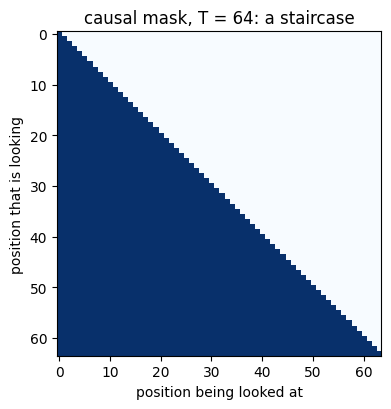

In [10]:
mask = np.tril(np.ones((CONTEXT, CONTEXT), dtype=int))
print("first 8 rows and columns of the mask (1 = may look, 0 = hidden):")
print(mask[:8, :8])
print("allowed cells:", mask.sum(), "of", mask.size, f"({mask.sum() / mask.size:.1%})")

plt.figure(figsize=(4.2, 4.2))
plt.imshow(mask, cmap="Blues", interpolation="nearest")
plt.xlabel("position being looked at"); plt.ylabel("position that is looking")
plt.title("causal mask, T = 64: a staircase")
plt.tight_layout(); plt.show()

---
## Step 11 - Prove that nothing leaks

A picture of a mask proves nothing about the model. This test does: take one window, change **one** character
at position 40, and compare the model's outputs before and after.

> **Predict:** which output positions are allowed to change: 0 to 39, 40 to 63, or all of them?

In [11]:
def leak_test(m, x, where=40):
    """Change the token at `where`; report how far the logits move before it and from it onwards."""
    a = np.array(x[:1])
    b = a.copy()
    b[0, where] = (b[0, where] + 1) % V
    la, lb = m.predict_on_batch(a), m.predict_on_batch(b)
    moved = np.abs(la - lb).max(axis=-1)[0]            # one number per position
    return float(moved[:where].max()), float(moved[where:].max())


before, after = leak_test(model, x_demo)
print(f"largest change at positions  0..39: {before:.6f}")
print(f"largest change at positions 40..63: {after:.6f}")
assert before < 1e-5, "the future is leaking into the past"

no_mask = build_tinygpt(V, causal=False)
before_nm, after_nm = leak_test(no_mask, x_demo)
print(f"same test, model built without the mask: positions 0..39 moved by up to {before_nm:.6f}")

largest change at positions  0..39: 0.000000
largest change at positions 40..63: 0.084764


same test, model built without the mask: positions 0..39 moved by up to 0.044296


### Why we see this

With the mask, positions 0 to 39 do not move by a single digit: nothing they compute depends on position 40.
Positions 40 onwards do move, as they should. Without the mask, every position moves. Keep this test. It
takes five lines and it catches the worst bug a language model can have (Step 18 shows what that bug does).

---
## Step 12 - The loss before training

The loss is cross-entropy between the model's 39 scores and the true next character, **averaged over every
position of every window**. The model outputs raw scores (logits), so the loss must be told:
`from_logits=True`.

An untrained model knows nothing, so it should spread its probability evenly and pay about ln V.

> **Predict:** the first loss, to two decimals. (You computed ln 39 in Step 4.)

In [12]:
loss_fn = keras.losses.SparseCategoricalCrossentropy(from_logits=True)
model.compile(loss=loss_fn)
first_loss = model.evaluate(x_val, y_val, batch_size=250, verbose=0)
print(f"loss before training: {first_loss:.3f}    ln V = {loss_blind:.3f}")

loud = build_tinygpt(V)
loud_weights = np.random.default_rng(0).normal(0, 0.14, size=(64, V)).astype("float32")
loud.get_layer("head").set_weights([loud_weights, np.zeros(V, "float32")])
loud.compile(loss=loss_fn)
print(f"same model, head weights of spread 0.14 instead of 0.02: {loud.evaluate(x_val, y_val, batch_size=250, verbose=0):.3f}")

loss before training: 3.633    ln V = 3.664


same model, head weights of spread 0.14 instead of 0.02: 4.218


### Why we see this

The first loss sits within a few hundredths of ln 39. That is a free test of the whole pipeline: shapes, shift, loss and
`from_logits` all have to be right for it to come out.

The second line shows what a louder head does. A standard deviation of 0.14 is what the default
initialiser of a `Dense(39)` on 64 inputs gives. The untrained model is then confidently wrong about
characters it has never studied, starts above ln V, and spends its first steps unlearning that confidence.
If your first loss is well above ln V, look at the initialisation of the head.

---
## Step 13 - A way to make it write

`generate()` runs the model in a loop: get the probability table for the next character, draw one character
from it, append it, repeat. Chapter 36 is about better ways to choose; here we draw from the model's own
table, unchanged.

One detail uses the causal mask. The model always takes 64 ids. When we have fewer, we put them on the left,
fill the rest with anything, and read the output at the last real position. The filler sits to its right, so
it cannot matter.

> **Predict:** what will an untrained model write?

In [13]:
def generate(model, prompt="\n", n_chars=200, temperature=1.0, seed=0):
    """Continue `prompt` by n_chars characters, drawing each from the model's probability table."""
    context = model.input_shape[1]
    g = np.random.default_rng(seed)
    ids = list(encode(prompt))
    for _ in range(n_chars):
        recent = ids[-context:]
        buf = np.zeros((1, context), dtype=np.int32)
        buf[0, :len(recent)] = recent                             # filler to the right is invisible
        logits = model.predict_on_batch(buf)[0, len(recent) - 1] / temperature
        p = np.exp(logits - logits.max())
        p /= p.sum()
        ids.append(int(g.choice(len(p), p=p)))
    return decode(ids)


print(repr(generate(model, "\n", 160)))

"\nl8'\ntwkpixt\nu p3ui9e 1nmlczznmoc2pi9fvxbj9kacv6l0tr6v'a3es5'c40k9o4xb0mxdygemzyergircqpx1qxz\nuzy2zvtf6sx7idx ql p\nqgx't'bdzi66v618kisi8dtmybiku2dw tdt\nb'n8px1v'"


---
## Step 14 - Train, and read the samples as they improve

The recipe is the standard one for transformers (Chapters 8 and 11): **AdamW**, a learning rate that warms up
over 100 steps and then follows a cosine down, gradient clipping at norm 1. Batch 64, 3,000 steps: 192,000
windows, about 12 million next-character questions. That is a little over three passes' worth of the corpus,
but the windows start at random places, so almost no window is seen twice.

We train in eight rounds and stop after each to measure the validation loss and print a sample from the same
seed.

> **Predict:** (1) roughly when will the loss pass the letter-frequency line and the bigram line of Step 4?
> (2) What will the writing look like at each of those moments?

> This is the slow cell: about two and a half minutes on a laptop CPU.

In [14]:
BATCH, STEPS, PEAK_LR = 64, 3000, 3e-3
schedule = keras.optimizers.schedules.CosineDecay(
    initial_learning_rate=0.0, warmup_target=PEAK_LR, warmup_steps=100,
    decay_steps=STEPS - 100, alpha=0.05)
model.compile(optimizer=keras.optimizers.AdamW(schedule, weight_decay=0.01, clipnorm=1.0), loss=loss_fn)

rounds = [50, 150, 300, 500, 500, 500, 500, 500]
assert sum(rounds) == STEPS
hist = {"step": [0], "val": [first_loss], "train_step": [], "train": []}
samples = {0: generate(model, "\n", 160)}
done, t0 = 0, time.time()
for n in rounds:
    x, y = random_windows(train_ids, n * BATCH)
    h = model.fit(x, y, batch_size=BATCH, epochs=1, shuffle=False, verbose=0)
    done += n
    val = model.evaluate(x_val, y_val, batch_size=250, verbose=0)
    hist["train_step"].append(done - n / 2); hist["train"].append(h.history["loss"][0])
    hist["step"].append(done); hist["val"].append(val)
    samples[done] = generate(model, "\n", 160)
    print(f"step {done:5d}  train {h.history['loss'][0]:.3f}  val {val:.3f}  perplexity {np.exp(val):5.2f}  [{time.time() - t0:4.0f}s]")
    print("   ", repr(samples[done][1:110]))
train_seconds = time.time() - t0
final_val = hist["val"][-1]

step    50  train 3.163  val 2.718  perplexity 15.15  [  12s]
    'nd  ttloius t rathed aonlezxonnd rheetteieieat3l tpat f is 1aa mcn we nuhuihlyuiregpeopt rtw tyv9xtre ttalgt '


step   200  train 2.380  val 2.271  perplexity  9.69  [  23s]
    "me asthe wo t't the acore yuripe sfemrten omes o tkes hanof ie n pewhart wheryrerennd27s sst twrawoth toblet "


step   500  train 1.961  val 1.788  perplexity  5.98  [  43s]
    "of arson't 19\nthis i corneys or but loward's the stioh cholal and creaster invonering's anlu turaws jels metc"


step  1000  train 1.684  val 1.628  perplexity  5.09  [  71s]
    'of anyonesh\nteriously plicys pomatic to perforenced the is all of creattion oworth this artu twr woth to mat '


step  1500  train 1.578  val 1.553  perplexity  4.72  [  95s]
    'placks sons termined and hywere but just going ratics feel amacherance ups involved his anny tvo work to mese'


step  2000  train 1.520  val 1.510  perplexity  4.53  [ 120s]
    'pecentary tas set he bloodyre that is the one every take that be sexacts whicks theatrit sus tventure treatua'


step  2500  train 1.485  val 1.482  perplexity  4.40  [ 144s]
    "ped to show the time but its one really man home to taken dap and dull until you're history astravenge's lite"


step  3000  train 1.457  val 1.470  perplexity  4.35  [ 168s]
    'pecent sort\nthis movie on you played to make the stereotype in remate or whengs them touchinator with the is '


### Why we see this

Read the samples against the two baselines of Step 4.

* **Before training:** every character equally likely, digits and apostrophes everywhere. Loss ≈ ln 39.
* **Around the letter-frequency line:** spaces and common letters in about the right proportions, so the
  output has "words" of plausible length made of the wrong letters. No context is being used yet.
* **Past the bigram line:** letter pairs are right, so fragments look pronounceable, and short real words
  appear (`the`, `and`, `of`).
* **By the end:** mostly real words, with invented ones that obey English spelling, and runs of three or four
  words that are grammatical. No sentence means anything, and nothing links one end of a line to the other.

The order is the lesson. Next-character prediction learns first whatever removes the most loss for the least
effort: frequencies, then pairs, then spelling, then local grammar. Meaning comes last, and it needs far more
model and far more text than this.

---
## Step 15 - The loss curve, with its landmarks

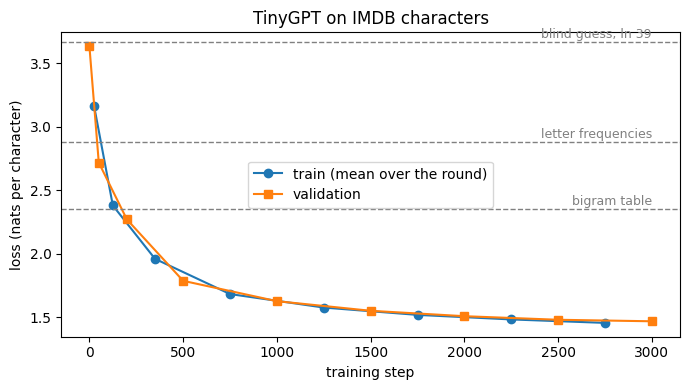

trained 3000 steps in 168 s
validation loss: 3.633 -> 1.470   (bigram table: 2.352)
last round: train 1.457, validation 1.470, gap +0.013


In [15]:
plt.figure(figsize=(7, 4))
plt.plot(hist["train_step"], hist["train"], "o-", label="train (mean over the round)")
plt.plot(hist["step"], hist["val"], "s-", label="validation")
for value, name in [(loss_blind, "blind guess, ln 39"), (loss_unigram, "letter frequencies"), (loss_bigram, "bigram table")]:
    plt.axhline(value, color="grey", linestyle="--", linewidth=1)
    plt.text(STEPS, value + 0.03, name, ha="right", fontsize=9, color="grey")
plt.xlabel("training step"); plt.ylabel("loss (nats per character)")
plt.title("TinyGPT on IMDB characters"); plt.legend(); plt.tight_layout(); plt.show()

print(f"trained {STEPS} steps in {train_seconds:.0f} s")
print(f"validation loss: {first_loss:.3f} -> {final_val:.3f}   (bigram table: {loss_bigram:.3f})")
print(f"last round: train {hist['train'][-1]:.3f}, validation {final_val:.3f}, gap {final_val - hist['train'][-1]:+.3f}")

### Why we see this

The loss falls fast, then slowly. Train and validation stay together: with 3.5 million characters and a
hundred thousand weights, this model has no room to memorise, so it is **underfitting**, not overfitting. More
steps, more width or more blocks would all still help. (Step 19 makes the opposite happen on purpose.)

---
## Step 16 - Perplexity: the loss, in units you can picture

Perplexity is *e* to the power of the loss. Read it as "the model is hesitating as if between this many
equally likely characters".

> **Predict:** the perplexity of a blind guess over 39 characters. Then the perplexity at the final loss.

In [16]:
for name, value in [("blind guess", loss_blind), ("letter frequencies", loss_unigram),
                    ("bigram table", loss_bigram), ("TinyGPT, validation", final_val)]:
    print(f"{name:22s} loss {value:.3f}   perplexity {np.exp(value):5.2f}")

blind guess            loss 3.664   perplexity 39.00
letter frequencies     loss 2.883   perplexity 17.87
bigram table           loss 2.352   perplexity 10.50
TinyGPT, validation    loss 1.470   perplexity  4.35


### Why we see this

The blind guess hesitates between 39 characters, exactly. TinyGPT has narrowed that to between four and five
on average. The average hides a lot: in the middle of a common word it is nearly certain, and at the start of
a new word it is nearly lost.

Perplexities are only comparable between models with the **same tokens**. A perplexity of 4 over characters
and a perplexity of 20 over subword tokens are not on the same scale (Chapter 33).

---
## Step 17 - Give it a prompt

> **Predict:** will the continuation stay on the subject of the prompt?

In [17]:
for seed, prompt in enumerate(["\nthis movie was ", "\nthe acting is ", "\ni have never seen "]):
    print(repr(generate(model, prompt, 150, seed=seed + 1)[1:]))
    print()

# the same random draws after two different prompts
p1, p2 = "\nthis movie was ", "\nthe acting is "
c1 = generate(model, p1, 150, seed=3)[len(p1):]
c2 = generate(model, p2, 150, seed=3)[len(p2):]
print("same seed, two prompts:")
print("  ", repr(c1[:90]))
print("  ", repr(c2[:90]))
print(f"   the two continuations agree at {np.mean([a == b for a, b in zip(c1, c2)]):.0%} of their 150 characters")

"this movie was long is nature keep they's development and from but excepting rip donne who rooting the girl and oker this full don't nothing a fetististry and lookin"



"the acting is beshion don't her if the vilbabsision this movie and this is a case is up only makes easidn't give because disapporte what informativately ed to disat"



"i have never seen about less of to rea wearbly she was spenion to the phone's coonves whipps hames fornike and riff i love maries heades to straight on member reason if"



same seed, two prompts:
   'a so in the history 194 where i rodrenger still the phooned contrates over halfd forre no '
   'a so in the history 194 where i rodney contrimulism sever of them thought agains espit of '
   the two continuations agree at 58% of their 150 characters


### Why we see this

It continues in the right register (film-review words, plausible spelling) and wanders off within a few words.
That is what a hundred thousand parameters and three minutes buy. It has learnt how reviews are spelt, not
what any film was about. Do not ask it questions.

Now compare the last two lines. They used the same random draws after two different prompts. Wherever they
agree, the model was not using the prompt at all: it was using only the last few characters, which the two
texts soon share. The window is 64 characters wide, but a model this small and this briefly trained leans
almost entirely on the nearest handful. A context window is what a model *may* use, not what it *does* use.

---
## Step 18 - What happens without the mask

The model in `no_mask` (Step 11) is TinyGPT with `causal=False`. The targets are the inputs shifted by one,
so the answer to "what comes after position t?" is sitting in the input at position t + 1, and without a mask
attention may look there.

> **Predict:** its training loss after 400 steps: higher or lower than TinyGPT's after 3,000? And what will it
> write?

In [18]:
no_mask.compile(optimizer=keras.optimizers.AdamW(1e-3, clipnorm=1.0), loss=loss_fn)
x, y = random_windows(train_ids, 400 * BATCH)
h = no_mask.fit(x, y, batch_size=BATCH, epochs=1, shuffle=False, verbose=0)
x_last, y_last = x[-50 * BATCH:], y[-50 * BATCH:]
nm_all = no_mask.evaluate(x_last, y_last, batch_size=250, verbose=0)
logits = no_mask.predict(x_last[:640], batch_size=128, verbose=0)
nm_last = float(loss_fn(y_last[:640, -1], logits[:, -1]))
nm_rest = float(loss_fn(y_last[:640, :-1], logits[:, :-1]))
print(f"no mask, after 400 steps: loss over all positions {nm_all:.3f}")
print(f"   positions 0..62 (the answer is one step to the right): {nm_rest:.3f}")
print(f"   position 63 (nothing to its right):                    {nm_last:.3f}")
peek = (logits[:, :-1].argmax(-1) == x_last[:640, 1:]).mean()
honest = (model.predict(x_val[:640], batch_size=128, verbose=0).argmax(-1) == y_val[:640]).mean()
print(f"   its top guess equals the character one step to the right: {peek:.1%} of the time")
print(f"   (TinyGPT, which cannot peek, gets the next character right {honest:.1%} of the time)")
print("it writes:", repr(generate(no_mask, "\nthis movie was ", 60)))

no mask, after 400 steps: loss over all positions 0.105
   positions 0..62 (the answer is one step to the right): 0.053
   position 63 (nothing to its right):                    3.265


   its top guess equals the character one step to the right: 99.7% of the time
   (TinyGPT, which cannot peek, gets the next character right 54.2% of the time)


it writes: "\nthis movie was d0\n\nqx896xq\nq\nl x3 3\n'6855zz9893 w8' xx58 800x280jj3m'517k3 "


### Why we see this

The loss is far below anything honest prediction could reach in 400 steps, and the breakdown shows why: at the
63 positions that have a right-hand neighbour, the model reads the answer off it. At the last position, where
there is nothing to copy, it is no better than a beginner.

Then ask it to write. At generation time the future does not exist: to the right of the last character there
is only filler. The one skill the model learnt, copying its right-hand neighbour, has nothing to work on, and
what comes out is junk. A wonderful training curve and a useless model: this is the bug the leak test of
Step 11 exists to catch.

---
## Step 19 - What memorising looks like

Now the opposite failure. Give a fresh TinyGPT only the first **2,000 characters** of the training text and
train it for 600 steps. It has 109,223 weights to describe 2,000 characters.

> **Predict:** the training loss and the validation loss at the end. Which of them is the honest one?

In [19]:
small_text = train_ids[:2000]
memo = build_tinygpt(V)
memo.compile(optimizer=keras.optimizers.AdamW(2e-3, clipnorm=1.0), loss=loss_fn)
memo_hist = []
for r in range(4):
    x, y = random_windows(small_text, 150 * BATCH)
    h = memo.fit(x, y, batch_size=BATCH, epochs=1, shuffle=False, verbose=0)
    v = memo.evaluate(x_val, y_val, batch_size=250, verbose=0)
    memo_hist.append((150 * (r + 1), h.history["loss"][0], v))
    print(f"step {150 * (r + 1):4d}  train {h.history['loss'][0]:.3f}  val {v:.3f}")
print()
print("the text it studied:", repr(decode(small_text[:90])))
print("what it writes     :", repr(generate(memo, decode(small_text[:20]), 70, seed=1)))

step  150  train 2.327  val 2.701


step  300  train 0.743  val 4.953


step  450  train 0.148  val 5.617


step  600  train 0.116  val 5.958

the text it studied: "this film was just brilliant casting location scenery story direction everyone's really su"


what it writes     : "this film was just brilliant casting location scenery story direction everyone's really su"


### Why we see this

The training loss heads for zero while the validation loss climbs past the blind-guess line: worse than
knowing nothing, because the model is now confidently reciting. Given the opening of the text it studied, it
continues it from memory. That looks like fluency and is the opposite of it.

This is why the validation text must not overlap the training text, and why a low training loss on a small
corpus is not a result. On text, **the gap between the two curves is the measurement**.

---
## Step 20 - Where the weights live: TinyGPT beside GPT-2 small

GPT-2 small (2019) is the same design: 12 blocks, width 768, feed-forward 3,072, context 1,024, a vocabulary of
50,257 subword tokens. One difference: its head has no weights of its own. It reuses the token table
(**weight tying**), so the head costs nothing.

> **Predict:** in which model do the tables hold the larger share of the weights? Why?

In [20]:
def share(parts):
    total = sum(parts.values())
    return {k: f"{v:>12,}  {v / total:6.1%}" for k, v in parts.items()}, total


tiny_parts, _, _, _ = count_tinygpt(V)
gpt2_parts, gpt2_block, _, _ = count_tinygpt(50257, d=768, heads=12, blocks=12, ff=3072, context=1024)
gpt2_untied = sum(gpt2_parts.values())
gpt2_parts["head"] = 0                                    # tied: the head is the token table, read backwards
for name, p in [("TinyGPT", tiny_parts), ("GPT-2 small (tied head)", gpt2_parts)]:
    rows, total = share(p)
    print(name)
    for k, v in rows.items():
        print(f"  {k:15s} {v}")
    print(f"  {'TOTAL':15s} {total:>12,}\n")
assert sum(gpt2_parts.values()) == 124_439_808 and gpt2_block == 7_087_872
print(f"GPT-2 small with an untied head would be {gpt2_untied:,}")
print(f"GPT-2 small is {sum(gpt2_parts.values()) / hand_total:,.0f} times TinyGPT")
print(f"TinyGPT with a tied head: {hand_total - V * 64:,}  (saves {V * 64:,})")
print(f"attention scores per head per layer: TinyGPT {64 * 64:,}, GPT-2 small {1024 * 1024:,}")
print(f"\nwhole notebook: {time.time() - t_start:.0f} s")

TinyGPT
  token table            2,496    2.3%
  position table         4,096    3.8%
  blocks                99,968   91.5%
  final norm               128    0.1%
  head                   2,535    2.3%
  TOTAL                109,223

GPT-2 small (tied head)
  token table       38,597,376   31.0%
  position table       786,432    0.6%
  blocks            85,054,464   68.3%
  final norm             1,536    0.0%
  head                       0    0.0%
  TOTAL            124,439,808

GPT-2 small with an untied head would be 163,087,441
GPT-2 small is 1,139 times TinyGPT
TinyGPT with a tied head: 106,727  (saves 2,496)
attention scores per head per layer: TinyGPT 4,096, GPT-2 small 1,048,576

whole notebook: 245 s


### Why we see this

The formula is the same; only the numbers change. With 39 characters, TinyGPT's token table is a rounding
error and the blocks hold over 90% of the model. With 50,257 tokens at width 768, GPT-2's token table alone is
31% of the model, and an untied head would add as much again. That is why tying matters at full size and
hardly matters here.

What does not scale from this notebook is everything outside the formula: GPT-2 was trained on about 40 GB of
web text, not 3.5 MB of reviews, on many GPUs for days, not one CPU for three minutes.

---
## Trials: change one thing at a time

| # | Change | Predict | Observe |
|---|---|---|---|
| 1 | Step 14: `STEPS = 6000` (and scale `rounds`) | Does validation loss still fall? By how much? | |
| 2 | Step 8: `build_tinygpt(V, blocks=1)` | Parameter count? Final loss higher by a little or a lot? | |
| 3 | Step 8: `build_tinygpt(V, d=128, ff=512)` | Parameter count (hand formula first). Time per step? | |
| 4 | Step 5 and 8: `CONTEXT = 16`, `context=16` | Which loss can it still beat: unigram, bigram? | |
| 5 | Step 14: `PEAK_LR = 3e-2` | Does it train, stall or blow up? | |
| 6 | Step 14: remove the warm-up (`warmup_steps=0`, `initial_learning_rate=PEAK_LR`) | What happens in the first 50 steps? | |
| 7 | Step 13: `temperature=0.5`, then `1.5` | Which sample has more real words? More variety? | |
| 8 | Step 19: 20,000 characters instead of 2,000 | Does validation loss still rise? | |

---
## Exercises

1. **Tie the head.** Write a layer whose output is `x @ transpose(token_table)` and use it in place of
   `Dense(V)`. Check that the parameter count falls by exactly 64·V + V or 64·V, depending on whether you keep
   a bias. Does the loss change?
2. **Contiguous chunks.** Replace `random_windows` with windows that tile the text end to end (start 0, 64,
   128, ...), shuffled. How many distinct windows are there? Train for the same number of steps and compare.
3. **Loss by position.** Compute the validation loss separately for each of the 64 positions and plot it. Why
   is position 0 the worst? Where does the curve flatten, and what does that tell you about how much context
   this model really uses?
4. **A custom loop.** Rewrite Step 14 with `tf.GradientTape`: forward pass, loss, gradients, clip,
   `optimizer.apply`. Log the gradient norm every 50 steps. When is it largest?
5. **Dropout.** Build `build_tinygpt(V, dropout=0.1)` and repeat Step 19. Does dropout delay the memorising?
   Then explain why `model.evaluate` and `generate` need no change to switch dropout off.
6. **Words, not characters.** Build a vocabulary of the 2,000 commonest words (plus an unknown token) and
   train the same model on word ids. Hand-count the new parameter total first. Why can you not compare its
   loss with the character model's?

---
## Cheat sheet

| Fact | Value / rule |
|---|---|
| The task | given tokens 0..t, a probability table for token t + 1, at every position at once |
| Input and target | the same window, target shifted left by one: `w[:, :-1]`, `w[:, 1:]` |
| Shapes | ids (batch, T) → vectors (batch, T, d) → blocks keep (batch, T, d) → logits (batch, T, V) |
| TinyGPT | d = 64, 4 heads, 2 pre-norm blocks, ff = 256, T = 64, V = 39, learnt positions, untied head |
| Parameters | V·d + T·d + blocks·(4d² + 4d + 2·d·ff + ff + d + 4d) + 2d + (d·V + V) = 109,223 |
| One block at d = 64 | attention 16,640 + feed-forward 33,088 + norms 256 = 49,984 |
| The one line that makes it a language model | `use_causal_mask=True` |
| Leak test | change a token at position p; outputs before p must not move |
| Loss | `SparseCategoricalCrossentropy(from_logits=True)`, averaged over every position |
| First loss | ≈ ln V = ln 39 = 3.664; much higher means the head starts too loud |
| Perplexity | e^loss; only comparable between models with the same tokens |
| Ladder to climb | blind guess → letter frequencies → bigram table → your model |
| Training recipe | AdamW, warm-up then cosine decay, clip gradients at norm 1 |
| Cheating | loss far too low, far too soon; garbage at generation: check the mask and the shift |
| Memorising | train loss falls, validation loss rises: split by document, watch the gap |
| GPT-2 small (2019) | 12 blocks, d = 768, T = 1,024, V = 50,257, tied head: 124,439,808 parameters |